# Dedicated MX E4M3/A32 — honderd-epochreferentie

Dit notebook analyseert **uitsluitend opgeslagen resultaten** van de dedicated E4M3-gewichtsreferentie: CNN-8/SVHN train-only, A32-activaties en een FP32-updatemaster. Er wordt geen training gestart en geen checkpoint geladen.

**Epoch100 is het vaste hoofdvergelijkingspunt.** Het beste E4M3-checkpoint wordt ernaast getoond; de laatste beschikbare epoch blijft afzonderlijk zichtbaar. Bij een onderbroken run wordt geen voltooiing of eindaccuracy verondersteld. Synthetische controlegegevens zijn bovenaan en in iedere figuurtitel herkenbaar gemarkeerd.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_e4m3_dedicated_reference100\\20261023_132558_081080_mx_run')
SAVE_FIGURES = True  # Nieuwe analysemap; ruwe resultaten blijven behouden.


In [2]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:  # Ook analyse vanuit een gewone Python-omgeving blijft mogelijk.
    class Markdown(str):
        pass
    def display(value):
        print(value)

sys.path.insert(0, str(RUN_DIR.expanduser().resolve()))
import notebook_support as ns

run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **100**.

**Volledige honderd-epochreferentie bevestigd.** Epoch100 is het vaste hoofdvergelijkingspunt; het beste checkpoint staat ernaast.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsformaat,MXFP8_E4M3
1,Activaties,A32
2,Updatemaster,float32
3,Interne cuDNN-convolutieprecisie,tf32
4,cuDNN benchmark / deterministische algoritmen,True / False
5,Dtype versus rekenprecisie,A32/FP32 benoemt tensor- en masterdtypes; de C...
6,Model,"svhnq, expand=2"
7,Data,svhn; train-split=train; extra=False
8,Train / test,73257 / 26032
9,Groepsgrootte / schaal,32 / E8M0


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch100, beste checkpoint en laatste beschikbare epoch

**Beste checkpoint:** het eerste strikte maximum van de opgeslagen E4M3-testaccuracy. Een gelijke score vervangt het eerdere beste checkpoint niet. Alle scores komen uit dezelfde dedicated run. De selectiebron en checkpointnaam staan expliciet in de tabel; een ontbrekend selectiebestand wordt niet als bevestigde selectie behandeld.

De officiële testset wordt volgens het bestaande protocol gebruikt voor selectie. De beste score is daarom **geen onafhankelijke testschatting na selectie**. Epoch100 blijft het vaste hoofdvergelijkingspunt. Zolang de run niet volledig als PASS is afgerond, toont het notebook de laatste beschikbare epoch en de beste score tot dan, zonder een epoch100-resultaat te voorspellen.


,Controlepunt,Epoch,Testaccuracy [%],Correct / n,CE-loss,Selectiebron,Checkpoint
0,Vast eindpunt epoch100,100,94.683466,24.648 / 26.032,0.263900,epoch_metrics/history; volledige referentie be...,vast epochnummer; geen nieuwe selectie
1,Beste E4M3-checkpoint,53,94.798709,24.678 / 26.032,0.237483,checkpoint_selection.json,best_checkpoint.pt
2,Laatste beschikbare epoch,100,94.683466,24.648 / 26.032,0.263900,checkpoint_selection.json,last_checkpoint.pt


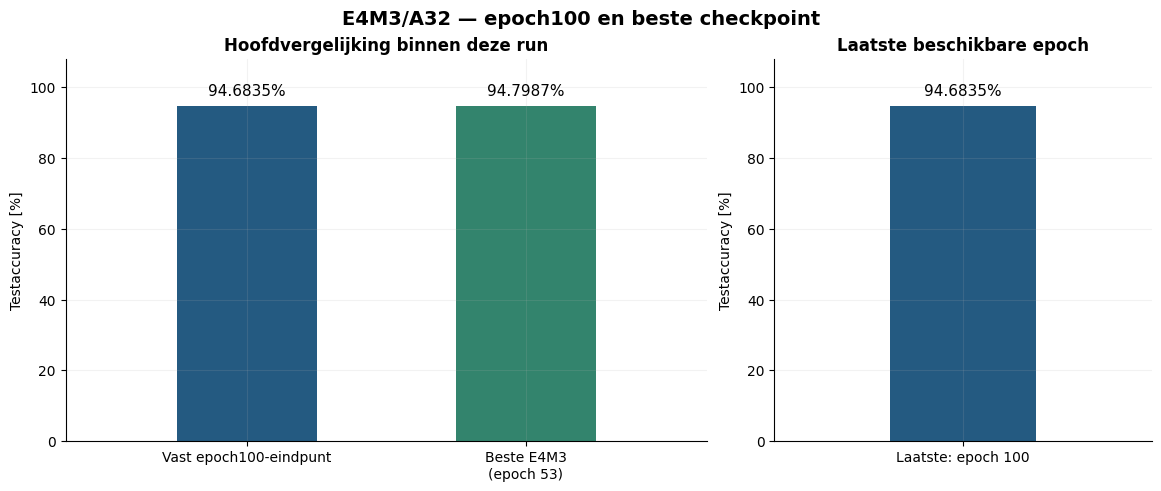

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'CE-loss': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Leercurves

Trainaccuracy en trainloss zijn tijdens de updates verzameld; testmetrics zijn na de epoch met bevroren evaluatiestaat gemeten. De figuur toont uitsluitend gemeten epochs.

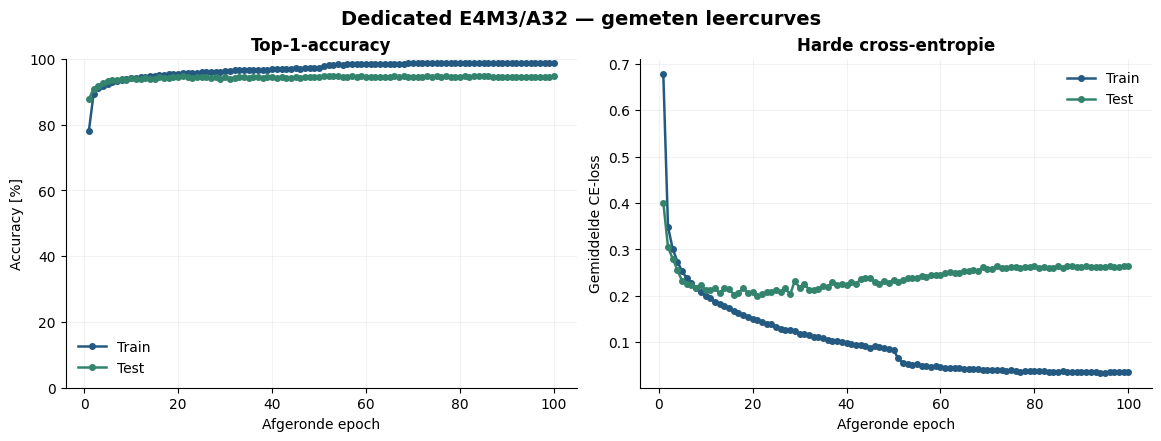

In [4]:
display(Markdown('## Leercurves\n\nTrainaccuracy en trainloss zijn tijdens de updates verzameld; testmetrics zijn na de epoch met bevroren evaluatiestaat gemeten. De figuur toont uitsluitend gemeten epochs.'))
figures['learning_curves'] = ns.plot_learning(run)
display(figures['learning_curves'])
plt.close(figures['learning_curves'])


## Gemeten looptijd

Bij een volledige referentie toont dit notebook de gemeten som van alle honderd epochtijden. Bij een onvolledige run blijft een opgeslagen looptijdprojectie als schatting herkenbaar.

**Gemeten duur over alle 100 epochs: 50.4 minuten (0.84 uur).** Dit is de som van de opgeslagen epochtijden, inclusief train, test, epochcontroles en checkpointschrijven. Download, installatie, data-inladen, eindrapportage en pauzes tussen sessies zijn niet inbegrepen. De figuur toont de gemeten totale duur; een eerdere looptijdprojectie wordt hiervoor niet gebruikt.

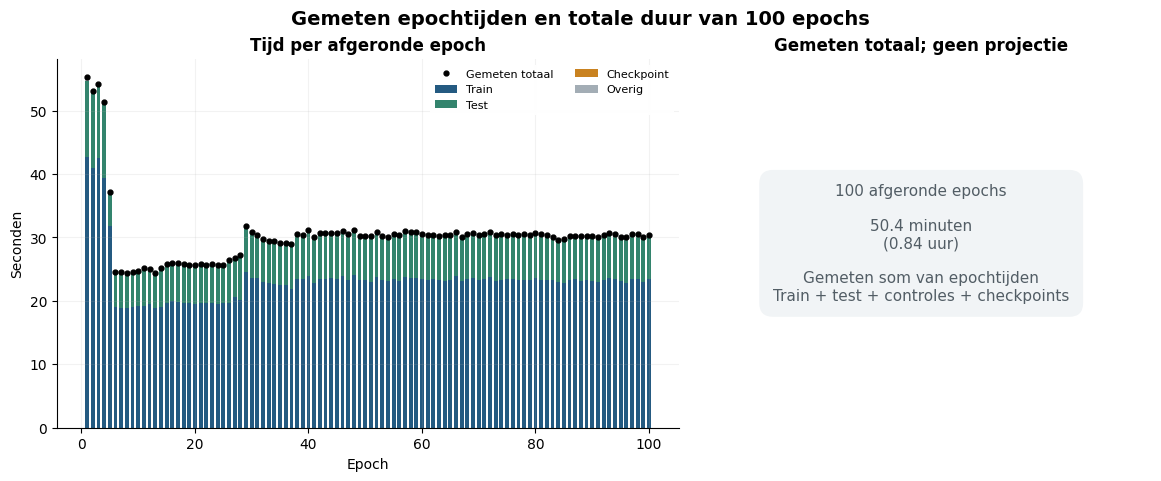

In [5]:
display(Markdown('## Gemeten looptijd\n\nBij een volledige referentie toont dit notebook de gemeten som van alle honderd epochtijden. Bij een onvolledige run blijft een opgeslagen looptijdprojectie als schatting herkenbaar.'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

Toegewezen en gereserveerd geheugen zijn de opgeslagen pieken van de PyTorch CUDA-allocator. Dit is geen meting van alle GPU-processen en geen bewijs van compacte native MX-uitvoering. Ontbrekende metingen blijven ontbrekend.

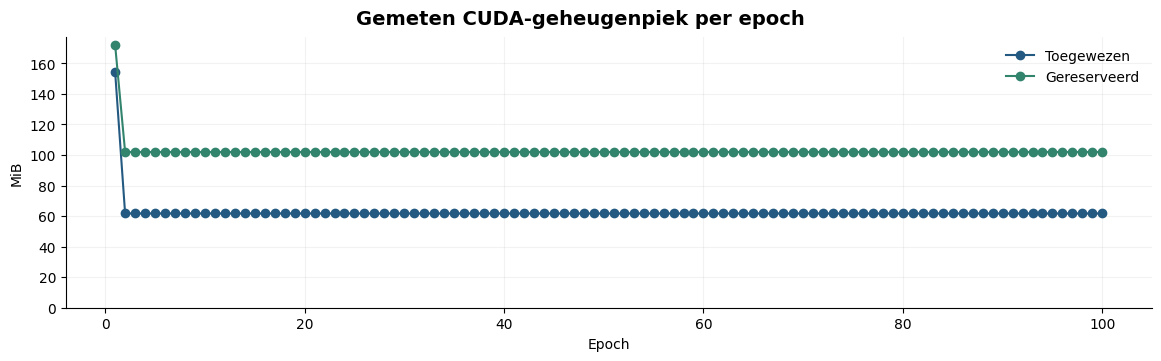

In [6]:
display(Markdown('## GPU-geheugen\n\nToegewezen en gereserveerd geheugen zijn de opgeslagen pieken van de PyTorch CUDA-allocator. Dit is geen meting van alle GPU-processen en geen bewijs van compacte native MX-uitvoering. Ontbrekende metingen blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [7]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabel rapporteert bestaande controles uit de run; het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates per epoch en doellaag'))
display(ns.weight_update_table(run))


## Opgeslagen technische controles

Deze tabel rapporteert bestaande controles uit de run; het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,Bronbestanden onveranderd,True
3,Ruwe datasetbestanden onveranderd,True
4,Optimizerupdates,57300
5,Selectie op officiële testset,True
6,Onafhankelijke testschatting,False


### Gewichtsupdates per epoch en doellaag

,epoch,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,layers.3,1728,1.171473,torch.float32,1647,7
1,1,layers.6,2304,1.312824,torch.float32,2211,13
2,1,layers.10,4608,1.992767,torch.float32,4406,37
3,1,layers.13,9216,2.918345,torch.float32,8951,24
4,1,layers.16,9216,2.986852,torch.float32,8981,16
...,...,...,...,...,...,...,...
595,100,layers.6,2304,0.001034,torch.float32,21,0
596,100,layers.10,4608,0.001455,torch.float32,43,0
597,100,layers.13,9214,0.002040,torch.float32,85,0
598,100,layers.16,9212,0.002164,torch.float32,76,0


## Interpretatie en grenzen

Een volledige honderd-epochrun levert een dedicated E4M3/A32-referentie voor deze workload en seed. Dit experiment bevat geen distillatie of exponenttruncatie en toont daarom nog geen winst van exponenttruncatie aan. De bestaande mantissaresultaten en latere gezamenlijke experimenten houden hun eigen resultaten en protocol.

A32 en FP32 beschrijven de activatie- en masterdtypes. De **opgeslagen CUDA-backendprecisie staat apart in de protocoltabel**: de cuDNN-convoluties kunnen intern TF32 gebruiken. De emulator levert geen meting van native MX-snelheid of energie. Bij een onderbroken of mislukte run blijven beschikbare epochs zichtbaar, samen met de runstatus en meldingen.

Met `SAVE_FIGURES = True` worden alleen de vier figuren en een analysemanifest naar een **nieuwe** map geschreven. Een volgende uitvoering maakt opnieuw een nieuwe map. Geen JSON, CSV, checkpoint of eerdere figuur wordt overschreven.


In [8]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')

print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [path.name for path in run.input_files]}))


Figuren opgeslagen in: C:\Users\renzo\master-thesis-mx\mx_runs\mx_e4m3_dedicated_reference100\20261023_132558_081080_mx_run\analysis_20261023_141936_891811
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_e4m3_dedicated_reference100\20261023_132558_081080_mx_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
